In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from cdrift import evaluation
from cdrift.utils.helpers import readCSV_Lists, convertToTimedelta, importLog
import numpy as np
from datetime import datetime
from statistics import mean, harmonic_mean, stdev
from scipy.stats import iqr
from typing import List
import seaborn as sns
import re
import json
import os
from pathlib import Path
import warnings

# Suppress all warnings
warnings.filterwarnings('ignore')

COUNT_DUPLICATE_DETECTIONS = False

LAG_WINDOW = 200
MIN_SUPPORT = 1 # Minimum support for latency calculation --> a parameter setting must have at least 3 instances where a true positive was detected before it can be deemed the "best parameter setting" for latency calculation

CSV_PATH = "evaluation_results/all_detections.csv" # Created by prepare_unified_evaluation.py
OUT_PATH = "evaluation_results/Unified_framework_results" if not COUNT_DUPLICATE_DETECTIONS else "evaluation_results/Unified_framework_results"
EvaluationLogs_path = "datasets/cdrift" # IMPORTANT TO SETUP: Write the path where you have Bose,Ceravolo and Ostovar datasets.


# Set to True to (re)create all_detections.csv and unified_framework_config.json from baselines_results/
PREPARE_DATA = True
if PREPARE_DATA:
    import prepare_unified_evaluation
    prepare_unified_evaluation.main()

# shorter_names, used_parameters and colors of all runs in baselines_results/, created by prepare_unified_evaluation.py
with open("evaluation_results/unified_framework_config.json") as f:
    _config = json.load(f)
shorter_names = _config["shorter_names"]
used_parameters = _config["used_parameters"]
colors = _config["colors"]

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Read baselines_results/adwin_combined_SM/detections.csv
Read baselines_results/adwin_standard/detections.csv
Read baselines_results/bose_combined_SM/detections.csv
Read baselines_results/bose_standard/detections.csv
Read baselines_results/emd_combined_CRE/detections.csv
Read baselines_results/emd_standard/detections.csv
Read baselines_results/vc_standard/detections.csv
Wrote 691 rows of 7 runs to evaluation_results/all_detections.csv and the config to evaluation_results/unified_framework_config.json
  VC_standard -> VC_standard
  adwin_combined_SM -> ADWIN_combined_SM
  adwin_standard -> ADWIN_standard
  bose_combined_SM -> Bose_combined_SM
  bose_standard -> Bose_standard
  emd_combined_CRE -> EMD_combined_CRE
  emd_standard -> EMD_standard


## Preprocessing

In [2]:
df = readCSV_Lists(CSV_PATH)
df.copy()

,Algorithm,Log Source,Log,Detected Changepoints,Actual Changepoints for Log,Duration (Seconds),Duration,Window Size,SW Step Size,Complexity Duration (Seconds),Threshold
0,adwin_combined_SM,Ceravolo,sudden_trace_noise10_1000_cd,[],[499],4.419267,0 days 00:00:04,NaN,NaN,NaN,NaN
1,adwin_combined_SM,Ceravolo,sudden_trace_noise10_1000_pl,[],[499],4.713537,0 days 00:00:04,NaN,NaN,NaN,NaN
2,adwin_combined_SM,Ceravolo,sudden_trace_noise15_1000_pm,[],[499],3.322847,0 days 00:00:03,NaN,NaN,NaN,NaN
3,adwin_combined_SM,Ceravolo,sudden_trace_noise15_1000_cf,[349],[499],4.135546,0 days 00:00:04,NaN,NaN,NaN,NaN
4,adwin_combined_SM,Ceravolo,sudden_trace_noise20_1000_cd,[],[499],4.257473,0 days 00:00:04,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
686,VC_standard,Ostovar,Composite_IOR_output_IOR_2,"[899, 1912]","[999, 1999]",2.906733,0 days 00:00:02,75.0,NaN,NaN,0.3
687,VC_standard,Ostovar,Composite_IRO_output_IRO_5,"[937, 1911]","[999, 1999]",2.820706,0 days 00:00:02,75.0,NaN,NaN,0.3
688,VC_standard,Ostovar,Atomic_ParallelMove_output_ParallelMove_2,"[937, 1913]","[999, 1999]",3.143647,0 days 00:00:03,75.0,NaN,NaN,0.3
689,VC_standard,Ostovar,Composite_RIO_output_RIO_2,"[895, 1912]","[999, 1999]",2.358779,0 days 00:00:02,75.0,NaN,NaN,0.3


### Exclude Martjushev WC (In favor of LCDD)

In [3]:
df = df[df["Algorithm"] != "Martjushev ADWIN WC"]

### Rename approaches to shorter names

#### IMPORTANT: ADD your approach here!!!

In [4]:
print(df["Algorithm"].unique())
# shorter_names = {
#     "Zheng DBSCAN": "RINV",
#     "Maaradji Runs": "ProDrift",
#     "Bose J": "J-Measure",
#     "Bose WC": "Window Count",
#     "Earth Mover's Distance": "EMD",
#     "Process Graph Metrics": "PGM",
#     "Martjushev ADWIN J": "ADWIN J",
#     "Martjushev ADWIN WC": "ADWIN WC",
#     "LCDD": "LCDD",
#     "Bernold":"VC",
#     "CV4CDD-4D":"CV4CDD",
#     "cluster_similarity" : "CS"
# }
df["Algorithm"] = df["Algorithm"].map(shorter_names)
df["Algorithm"].unique()

['adwin_combined_SM' 'adwin_standard' 'bose_combined_SM' 'bose_standard'
 'emd_combined_CRE' 'emd_standard' 'VC_standard']


array(['ADWIN_combined_SM', 'ADWIN_standard', 'Bose_combined_SM',
       'Bose_standard', 'EMD_combined_CRE', 'EMD_standard', 'VC_standard'],
      dtype=object)

In [5]:
# Order in which to plot the approaches, to stay consistent
ALPHA_SORT_NAMES = sorted(list(df["Algorithm"].unique()))
ALPHA_SORT_NAMES

['ADWIN_combined_SM',
 'ADWIN_standard',
 'Bose_combined_SM',
 'Bose_standard',
 'EMD_combined_CRE',
 'EMD_standard',
 'VC_standard']

### Only use Atomic Logs

In [6]:
atomic_logs = {
    log
    for index, (source, log) in df[["Log Source", "Log"]].iterrows()
    if (source.lower() == "ostovar" and log.lower().startswith("atomic")) # Only use atomic logs from ostovar
    or (log.lower().startswith("bose")) # Use bose log
    or (source.lower() == "ceravolo" and set(log.lower().split("_")[-1]) != {'i', 'o', 'r'}) # Exclude all composite (IOR, ROI, etc.) logs from ceravolo
}

df = df[df["Log"].isin(atomic_logs)]

### Calculate Log Lengths for Scalability

In [7]:
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

# --- Helper for parallel execution ---
def load_log_lengths(logpath_str):
    """Load one log file and return its lengths safely."""

    log = importLog(logpath_str, verbose=False)
    cases = len(log)
    events = sum(len(case) for case in log)
    return logpath_str, cases, events


# --- Build logpaths exactly as before ---
_groupkeys = list(df.groupby(["Log Source", "Log"]).groups.keys())
_logpaths = [Path(EvaluationLogs_path, source, f"{log}.xes.gz") for source, log in _groupkeys]


# --- Run in parallel ---
loglengths = {}
loglengths_events = {}

with ProcessPoolExecutor() as executor:
    futures = executor.map(
        load_log_lengths,
        (p.as_posix() for p in _logpaths)
    )

    for logpath_str, case_len, evt_len in futures:
        loglengths[logpath_str] = case_len
        loglengths_events[logpath_str] = evt_len


In [8]:
print(f"Number of Logs: {len(loglengths.keys())}")
print(f"Number of Cases: {sum(loglengths.values())}")
print(f"Number of Events: {sum(loglengths_events.values())}")

Number of Logs: 90
Number of Cases: 172961
Number of Events: 4508965


##### Number of Drifts

In [9]:
num_drifts = sum(
    len(group.iloc[0]["Actual Changepoints for Log"])
    for name, group in df.groupby(["Log Source", "Log"])
)
print("Total number of drifts:", num_drifts)

Total number of drifts: 132


### Check for Duplicate Rows (Sanity Check)

In [10]:
def split_by_name(df):
    return [
        (alg, df[df["Algorithm"] == alg].copy())
        for alg in df["Algorithm"].unique()
    ]

dfs = split_by_name(df)

if not pd.read_csv(CSV_PATH).duplicated().any():
    print("No duplicate rows in the Dataframe! :)")
else:
    for name, d in split_by_name(pd.read_csv(CSV_PATH)):
        print(f"{name} contains duplicate rows: {d.duplicated().any()}")

df

No duplicate rows in the Dataframe! :)


,Algorithm,Log Source,Log,Detected Changepoints,Actual Changepoints for Log,Duration (Seconds),Duration,Window Size,SW Step Size,Complexity Duration (Seconds),Threshold
0,ADWIN_combined_SM,Ceravolo,sudden_trace_noise10_1000_cd,[],[499],4.419267,0 days 00:00:04,NaN,NaN,NaN,NaN
1,ADWIN_combined_SM,Ceravolo,sudden_trace_noise10_1000_pl,[],[499],4.713537,0 days 00:00:04,NaN,NaN,NaN,NaN
2,ADWIN_combined_SM,Ceravolo,sudden_trace_noise15_1000_pm,[],[499],3.322847,0 days 00:00:03,NaN,NaN,NaN,NaN
3,ADWIN_combined_SM,Ceravolo,sudden_trace_noise15_1000_cf,[349],[499],4.135546,0 days 00:00:04,NaN,NaN,NaN,NaN
4,ADWIN_combined_SM,Ceravolo,sudden_trace_noise20_1000_cd,[],[499],4.257473,0 days 00:00:04,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
678,VC_standard,Ostovar,Atomic_ParallelRemoval_output_ParallelRemoval_2,"[898, 1912]","[999, 1999]",2.563096,0 days 00:00:02,75.0,NaN,NaN,0.3
679,VC_standard,Ostovar,Atomic_ParallelMove_output_ParallelMove_5,"[898, 1911]","[999, 1999]",2.673548,0 days 00:00:02,75.0,NaN,NaN,0.3
680,VC_standard,Ostovar,Atomic_ConditionalToSequence_output_Conditiona...,"[934, 1912]","[999, 1999]",2.986387,0 days 00:00:02,75.0,NaN,NaN,0.3
681,VC_standard,Ostovar,Atomic_ParallelToSequence_output_ParallelToSeq...,"[935, 1912]","[999, 1999]",2.721580,0 days 00:00:02,75.0,NaN,NaN,0.3


### Add Auxiliary Columns for Noise and Change Pattern
- One column stating the change pattern used in this event log
- One column stating the noise level

In [11]:
mapping_ostovar_to_shortnames = {
    "ConditionalMove": 'cm',
    "ConditionalRemoval": 'cre',
    "ConditionalToSequence": 'cf',
    "Frequency": 'fr',
    "Loop": 'lp',
    "ParallelMove": 'pm',
    "ParallelRemoval": 'pre',
    "ParallelToSequence": 'pl',
    "SerialMove": 'sm',
    "SerialRemoval": 'sre',
    "Skip": 'cb',
    "Substitute": 'rp',
    "Swap": 'sw',
}

def map_row_to_cp(row):
    logname = row["Log"]
    if row["Log Source"] == "Ceravolo":
        return logname.split("_")[-1]
    elif row["Log Source"] == "Ostovar":
        change_pattern = logname.split("_")[-1]
        if change_pattern.isnumeric(): # This log has a noise level; Use the second to last string instead
            change_pattern = logname.split("_")[-2]
        return mapping_ostovar_to_shortnames[change_pattern]
    elif row["Log Source"] == "Bose":
        return None
    else:
        raise ValueError(f"Unknown Log Source for Versatility: {row['Log Source']}; Is this Log meant to be used for a Versatility Evaluation?")

# Add a column stating the change pattern that is applied
df["Change Pattern"] = df.apply(lambda x: map_row_to_cp(x), axis=1)

In [12]:
# Preprocessing; Add "Noise Level" Column
def map_row_to_noise(row):
    logname = row["Log"]
    if row["Log Source"] == "Ceravolo":
        return re.search('noise([0-9]*)_', logname).group(1)
    elif row["Log Source"] == "Ostovar":
        # return mapping_ostovar_to_shortnames[logname.split("_")[-1]]
        last_member = logname.split('_')[-1]
        if last_member.isnumeric():
            return last_member
        else:
            return '0'
    elif row["Log Source"] == "Bose":
        return None
    else:
        raise ValueError(f"Unknown Log Source for Noise Level: {row['Log Source']}; Is this Log meant to be used for a Robustness Evaluation?")

# Only use the Ceravolo and Ostovar Logs as Bose has only 1 log, i.e., no noise levels
# Add a column stating the change pattern that is applied and one for the noise level
df["Noise Level"] = df.apply(lambda x: map_row_to_noise(x), axis=1)
df[['Algorithm', 'Log Source', 'Log', 'Change Pattern', 'Noise Level']]

,Algorithm,Log Source,Log,Change Pattern,Noise Level
0,ADWIN_combined_SM,Ceravolo,sudden_trace_noise10_1000_cd,cd,10
1,ADWIN_combined_SM,Ceravolo,sudden_trace_noise10_1000_pl,pl,10
2,ADWIN_combined_SM,Ceravolo,sudden_trace_noise15_1000_pm,pm,15
3,ADWIN_combined_SM,Ceravolo,sudden_trace_noise15_1000_cf,cf,15
4,ADWIN_combined_SM,Ceravolo,sudden_trace_noise20_1000_cd,cd,20
...,...,...,...,...,...
678,VC_standard,Ostovar,Atomic_ParallelRemoval_output_ParallelRemoval_2,pre,2
679,VC_standard,Ostovar,Atomic_ParallelMove_output_ParallelMove_5,pm,5
680,VC_standard,Ostovar,Atomic_ConditionalToSequence_output_Conditiona...,cf,5
681,VC_standard,Ostovar,Atomic_ParallelToSequence_output_ParallelToSeq...,pl,0


### Split into Noisy/Noiseful Logs

In [13]:
logs = zip(df["Log Source"], df["Log"])

noiseless_logs = {
    log for source, log in logs if 
    (source == "Ostovar"  and not (log.endswith("_2") or log.endswith("_5"))) or
    (source == "Ceravolo" and log.split("_")[2]=="noise0") or
    source == "Bose"
}

df_noiseless = df[df["Log"].isin(noiseless_logs)]
df_noisy = df[df["Log"].isin(noiseless_logs) == False]

dfs_noisy = split_by_name(df_noisy)
dfs_noiseless = split_by_name(df_noiseless)

In [14]:
dfs_noisy

[('ADWIN_combined_SM',
              Algorithm Log Source  \
  0   ADWIN_combined_SM   Ceravolo   
  1   ADWIN_combined_SM   Ceravolo   
  2   ADWIN_combined_SM   Ceravolo   
  3   ADWIN_combined_SM   Ceravolo   
  4   ADWIN_combined_SM   Ceravolo   
  ..                ...        ...   
  84  ADWIN_combined_SM    Ostovar   
  85  ADWIN_combined_SM    Ostovar   
  87  ADWIN_combined_SM    Ostovar   
  88  ADWIN_combined_SM    Ostovar   
  89  ADWIN_combined_SM    Ostovar   
  
                                                  Log Detected Changepoints  \
  0                      sudden_trace_noise10_1000_cd                    []   
  1                      sudden_trace_noise10_1000_pl                    []   
  2                      sudden_trace_noise15_1000_pm                    []   
  3                      sudden_trace_noise15_1000_cf                 [349]   
  4                      sudden_trace_noise20_1000_cd                    []   
  ..                                        

In [15]:
dfs_noiseless

[('ADWIN_combined_SM',
              Algorithm Log Source  \
  7   ADWIN_combined_SM   Ceravolo   
  9   ADWIN_combined_SM   Ceravolo   
  14  ADWIN_combined_SM   Ceravolo   
  15  ADWIN_combined_SM   Ceravolo   
  20  ADWIN_combined_SM   Ceravolo   
  33  ADWIN_combined_SM   Ceravolo   
  38  ADWIN_combined_SM   Ceravolo   
  40  ADWIN_combined_SM   Ceravolo   
  41  ADWIN_combined_SM   Ceravolo   
  46  ADWIN_combined_SM   Ceravolo   
  50  ADWIN_combined_SM       Bose   
  51  ADWIN_combined_SM    Ostovar   
  54  ADWIN_combined_SM    Ostovar   
  55  ADWIN_combined_SM    Ostovar   
  56  ADWIN_combined_SM    Ostovar   
  57  ADWIN_combined_SM    Ostovar   
  58  ADWIN_combined_SM    Ostovar   
  59  ADWIN_combined_SM    Ostovar   
  60  ADWIN_combined_SM    Ostovar   
  63  ADWIN_combined_SM    Ostovar   
  72  ADWIN_combined_SM    Ostovar   
  74  ADWIN_combined_SM    Ostovar   
  81  ADWIN_combined_SM    Ostovar   
  86  ADWIN_combined_SM    Ostovar   
  
                        

### Define Color Schema

#### IMPORTANT: ADD your approach here!!! Because you added one more approach, you need to add one more color

In [16]:
# colors = ["#DB444B","#9A607F","#006BA2","#3EBCD2","#379A8B","#EBB434","#B4BA39","#D1B07C","#8E44AD","#FF7F50"]
color_map = {ALPHA_SORT_NAMES[i]:colors[i] for i in range(0,len(ALPHA_SORT_NAMES))}

## Analyze Change Pattern Distribution

In [17]:
print(df["Change Pattern"].unique()) # None means Bose

cp_count_results = { cp: dict() for cp in df["Change Pattern"].unique() if cp is not None } # Bose gets lost because it maps to none

for name, group in df[["Log Source", "Log", "Change Pattern"]].drop_duplicates(inplace=False).groupby("Log Source"): # Only consider each logpath once (not once for each algorithm application)
    series = group["Change Pattern"].value_counts().to_dict()
    for cp, count in series.items():
        cp_count_results[cp][name] = count

for key in cp_count_results.keys():
    cp_count_results[key]["Bose"] = 0
cp_count_results["Mixed (Bose)"] = {"Ostovar": 0, "Ceravolo": 0, "Bose": 1}

    
cp_counts = pd.DataFrame(cp_count_results).fillna(0).astype(int)
cp_counts


['cd' 'pl' 'pm' 'cf' 'sw' 'cb' 're' 'lp' 'rp' 'cp' None 'fr' 'pre' 'cre'
 'sre' 'sm' 'cm']


,cd,pl,pm,cf,sw,cb,re,lp,rp,cp,fr,pre,cre,sre,sm,cm,Mixed (Bose)
Ceravolo,5,5,5,5,5,5,5,5,5,5,0,0,0,0,0,0,0
Bose,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
Ostovar,0,3,3,3,3,3,0,3,3,0,3,3,3,3,3,3,0


#### Compute Relative Counts

In [18]:
cp_counts_tr = cp_counts.transpose()
total_logs = cp_counts.to_numpy().sum()
cp_counts_tr["Relative Frequency"] = cp_counts_tr.apply(lambda row: row.sum() / total_logs * 100, axis=1)
cp_counts_tr

,Ceravolo,Bose,Ostovar,Relative Frequency
cd,5,0,0,5.555556
pl,5,0,3,8.888889
pm,5,0,3,8.888889
cf,5,0,3,8.888889
sw,5,0,3,8.888889
cb,5,0,3,8.888889
re,5,0,0,5.555556
lp,5,0,3,8.888889
rp,5,0,3,8.888889
cp,5,0,0,5.555556


## Accuracy for latency percentages
- Lags of 0.05,0.025,0.01 % latency
- All Change-Patterns
- All dataset
- Max cummulative *Recall* achieved of all parameter settings
  - Accumulate TP and FP over all event logs before calculating recall

In [19]:
df["Algorithm"].unique()

array(['ADWIN_combined_SM', 'ADWIN_standard', 'Bose_combined_SM',
       'Bose_standard', 'EMD_combined_CRE', 'EMD_standard', 'VC_standard'],
      dtype=object)

#### IMPORTANT: ADD your approach here!!!

In [20]:
from joblib import Parallel, delayed

# used_parameters = {
#         "Bose J": ["Window Size", "SW Step Size"],
#         "Bose WC": ["Window Size", "SW Step Size"],
#         "Martjushev ADWIN J": ["Min Adaptive Window", "Max Adaptive Window", "P-Value", "ADWIN Step Size"],
#         "Martjushev ADWIN WC": ["Min Adaptive Window", "Max Adaptive Window", "P-Value", "ADWIN Step Size"],
#         "Maaradji Runs": ["Window Size", "SW Step Size"],
#         "Earth Mover's Distance": ["Window Size", "SW Step Size"],
#         "Process Graph Metrics": ["Min Adaptive Window", "Max Adaptive Window", "P-Value"],
#         "Zheng DBSCAN": ["MRID", "Epsilon"],
#         "LCDD": ["Complete-Window Size", "Detection-Window Size", "Stable Period"],
#         "Bernold": ["Window Size"],
#         "CV4CDD-4D": ["Window Size"],
#         "cluster_similarity": ["Window Size"],
#     }

# # --- Optimized used_parameters mapping ---
# used_parameters = {
#     shorter_names[name]: params
#     for name, params in used_parameters.items()
# }

def compute_lag_window_from_loglengths(sample_row, lag_percentage, loglengths):
    log_source = sample_row["Log Source"]
    log_name   = sample_row["Log"]

    key_path = f"{EvaluationLogs_path}/{log_source}/{log_name}.xes.gz"

    if key_path not in loglengths:
        raise KeyError(f"Log length missing for: {key_path}")

    log_size = loglengths[key_path]
    return int(log_size * lag_percentage)


def calcAccuracy(df: pd.DataFrame, param_names: List[str], lag_percentage: float, loglengths=None):
    f1s = {}
    recalls = {}
    precisions = {}

    col_actual = "Actual Changepoints for Log"
    col_detected = "Detected Changepoints"
    idx_actual = df.columns.get_loc(col_actual)
    idx_detected = df.columns.get_loc(col_detected)

    # Compute lag window ONCE per group of parameters
    for parameters, group in df.groupby(param_names):

        sample_row = group.iloc[0]  # for log identification
        lag_window = compute_lag_window_from_loglengths(sample_row, lag_percentage, loglengths)

        tps = fps = positives = detected = 0

        for row in group.itertuples(index=False):
            actual_cp = row[idx_actual]
            detected_cp = row[idx_detected]

            tp, fp = evaluation.getTP_FP(
                detected_cp, actual_cp, lag_window,
                count_duplicate_detections=False
            )

            tps += tp
            fps += fp
            positives += len(actual_cp)
            detected += tp + fp

        precisions[parameters] = tps / detected if detected else np.nan
        recalls[parameters] = tps / positives if positives else np.nan
        f1s[parameters] = harmonic_mean([precisions[parameters], recalls[parameters]])

    return precisions, recalls, f1s



def process_algorithm(name, a_df, lag_percentage, loglengths):
    prec, rec, acc = calcAccuracy(a_df, used_parameters[name], lag_percentage, loglengths)

    best_param = max(acc, key=acc.get)
    best_acc = acc[best_param]

    return name, prec, rec, acc, best_param, best_acc


def calculate_accuracy_metric_df(dataframe, lag_percentage, loglengths, verbose=True):
    groups = [(name, a_df) for name, a_df in dataframe.groupby("Algorithm")]

    results = Parallel(n_jobs=-1)(
        delayed(process_algorithm)(name, a_df, lag_percentage, loglengths)
        for name, a_df in groups
    )

    computed_accuracy_dicts = {}
    computed_precision_dicts = {}
    computed_recall_dicts = {}
    accuracy_best_param = {}
    accuracies = {}

    for name, prec, rec, acc, best_param, best_acc in results:
        computed_precision_dicts[name] = prec
        computed_recall_dicts[name] = rec
        computed_accuracy_dicts[name] = acc
        accuracy_best_param[name] = best_param
        accuracies[name] = best_acc

        if verbose:
            print(f"{name}: {best_acc}")

    return (
        accuracies,
        computed_accuracy_dicts,
        computed_precision_dicts,
        computed_recall_dicts,
        accuracy_best_param
    )

LAG_PERCENTAGES = [0.01,0.025,0.05]

for LAG_PERCENTAGE in LAG_PERCENTAGES:
    print(f"Lag percentage: {LAG_PERCENTAGE}")

    accuracies, computed_accuracy_dicts, computed_precision_dicts, \
    computed_recall_dicts, accuracy_best_param = \
        calculate_accuracy_metric_df(df, LAG_PERCENTAGE, loglengths, verbose=False)
    
    pd.DataFrame(
        [{'Algorithm': name, 'Accuracy': accuracies[name]} for name in accuracies.keys()]
    ).sort_values(by="Algorithm", ascending=True)
    
    accuracy_plot_df = pd.DataFrame(
        [
            {
                "Algorithm": name,
                "Metric": "F1-Score",
                "Value": computed_accuracy_dicts[name][accuracy_best_param[name]]
            }
            for name in computed_accuracy_dicts.keys()
        ] + [
            {
                "Algorithm": name,
                "Metric": "Precision",
                "Value": computed_precision_dicts[name][accuracy_best_param[name]]
            }
            for name in computed_accuracy_dicts.keys()
        ] + [
            {
                "Algorithm": name,
                "Metric": "Recall",
                "Value": computed_recall_dicts[name][accuracy_best_param[name]]
            }
            for name in computed_accuracy_dicts.keys()
        ]
    )
    print(accuracy_plot_df)

Lag percentage: 0.01
            Algorithm     Metric     Value
0   ADWIN_combined_SM   F1-Score  0.067227
1      ADWIN_standard   F1-Score  0.052632
2    Bose_combined_SM   F1-Score  0.096970
3       Bose_standard   F1-Score  0.020619
4    EMD_combined_CRE   F1-Score  0.284644
5        EMD_standard   F1-Score  0.625483
6         VC_standard   F1-Score  0.330709
7   ADWIN_combined_SM  Precision  0.075472
8      ADWIN_standard  Precision  0.086207
9    Bose_combined_SM  Precision  0.080808
10      Bose_standard  Precision  0.018868
11   EMD_combined_CRE  Precision  0.281481
12       EMD_standard  Precision  0.637795
13        VC_standard  Precision  0.344262
14  ADWIN_combined_SM     Recall  0.060606
15     ADWIN_standard     Recall  0.037879
16   Bose_combined_SM     Recall  0.121212
17      Bose_standard     Recall  0.022727
18   EMD_combined_CRE     Recall  0.287879
19       EMD_standard     Recall  0.613636
20        VC_standard     Recall  0.318182
Lag percentage: 0.025
           

# Accuracy
- All Change-Patterns
- Only 0 Noise
- Max cummulative Recall achieved of all parameter settings
    - Accumulate TP and FP over all event logs before calculating recall

In [21]:
df["Algorithm"].unique()

array(['ADWIN_combined_SM', 'ADWIN_standard', 'Bose_combined_SM',
       'Bose_standard', 'EMD_combined_CRE', 'EMD_standard', 'VC_standard'],
      dtype=object)

#### IMPORTANT: ADD your approach here!!!

In [22]:
# used_parameters = {
#         "Bose J": ["Window Size", "SW Step Size"],
#         "Bose WC": ["Window Size", "SW Step Size"],
#         "Martjushev ADWIN J": ["Min Adaptive Window", "Max Adaptive Window", "P-Value", "ADWIN Step Size"],
#         "Martjushev ADWIN WC": ["Min Adaptive Window", "Max Adaptive Window", "P-Value", "ADWIN Step Size"],
#         "Maaradji Runs": ["Window Size", "SW Step Size"],
#         "Earth Mover's Distance": ["Window Size", "SW Step Size"],
#         "Process Graph Metrics": ["Min Adaptive Window", "Max Adaptive Window", "P-Value"],
#         "Zheng DBSCAN": ["MRID", "Epsilon"],
#         "LCDD": ["Complete-Window Size", "Detection-Window Size", "Stable Period"],
#         "Bernold": ["Window Size"],
#         "CV4CDD-4D": ["Window Size"],
#         "cluster_similarity": ["Window Size"],
#     }

# used_parameters = {
#     shorter_names[name]: used_parameters[name]
#     for name in used_parameters.keys()
# }



def calcAccuracy(df:pd.DataFrame, param_names:List[str], lag_window: int):
    """Calculates the Accuracy Metric for the given dataframe by grouping by the given parameters and calculating the mean accuracy

    Args:
        df (pd.DataFrame): The dataframe containing the results to be evaluated
        param_names (List[str]): The names of the parameters of this approach
        lag_window (int): The lag window to be used for the evaluation to determine true positives and false positives

    Returns:
        _type_: _description_
    """

    f1s = dict()
    recalls = dict()
    precisions = dict()
    # Group by parameter values to calculate accuracy per parameter setting, over all logs
    for parameters, group in df.groupby(by=param_names):
        # Calculate Accuracy for this parameter setting
        ## --> F1-Score, but first collect all TP and FP
        tps = 0
        fps = 0
        positives = 0
        detected = 0

        # Collect TP FP, etc. 
        for index, row in group.iterrows():
            actual_cp = row["Actual Changepoints for Log"]
            detected_cp = row["Detected Changepoints"]
            tp, fp = evaluation.getTP_FP(detected_cp, actual_cp, lag_window, count_duplicate_detections=False)
            tps += tp
            fps += fp
            positives += len(actual_cp)
            detected += tp + fp

        try:
            precisions[parameters] = tps / detected # Not counting duplicates would decrease `detected=tps+fps`, i.e., increase precision
        except ZeroDivisionError:
            precisions[parameters] = np.NaN
        
        try:
            recalls[parameters] = tps / positives # Not counting duplicates would have no effect on the recall
        except ZeroDivisionError:
            recalls[parameters] = np.NaN

        f1s[parameters] = harmonic_mean([precisions[parameters], recalls[parameters]]) # If either is nan, the harmonic mean is nan
    return (precisions, recalls, f1s)

def calculate_accuracy_metric_df(dataframe, lag_window, verbose=True):
    computed_accuracy_dicts = dict()
    computed_precision_dicts = dict()
    computed_recall_dicts = dict()

    accuracy_best_param = dict()

    accuracies = dict()
    for name, a_df in dataframe.groupby(by="Algorithm"):
        computed_precision_dicts[name], computed_recall_dicts[name], computed_accuracy_dicts[name] = calcAccuracy(a_df, used_parameters[name], lag_window)

        best_param = max(computed_accuracy_dicts[name],  key=lambda x: computed_accuracy_dicts[name][x])

        accuracy_best_param[name] = best_param

        # accuracies[name] = max(computed_accuracy_dicts[name].values())
        accuracies[name] = computed_accuracy_dicts[name][best_param]
        if verbose:
            print(f"{name}: {accuracies[name]}")

    return (accuracies, computed_accuracy_dicts, computed_precision_dicts, computed_recall_dicts, accuracy_best_param)

accuracies, computed_accuracy_dicts, computed_precision_dicts, computed_recall_dicts, accuracy_best_param = calculate_accuracy_metric_df(df_noiseless, LAG_WINDOW, verbose=False)

pd.DataFrame([{'Algorithm': name, 'Accuracy': accuracies[name]} for name in accuracies.keys()]).sort_values(by="Algorithm", ascending=True)

,Algorithm,Accuracy
0,ADWIN_combined_SM,0.831169
1,ADWIN_standard,0.750000
2,Bose_combined_SM,0.674419
3,Bose_standard,0.790123
4,EMD_combined_CRE,0.765432
5,EMD_standard,0.833333
6,VC_standard,0.897436


#### Plot Accuracy as Barplot of Precision, Recall, F1

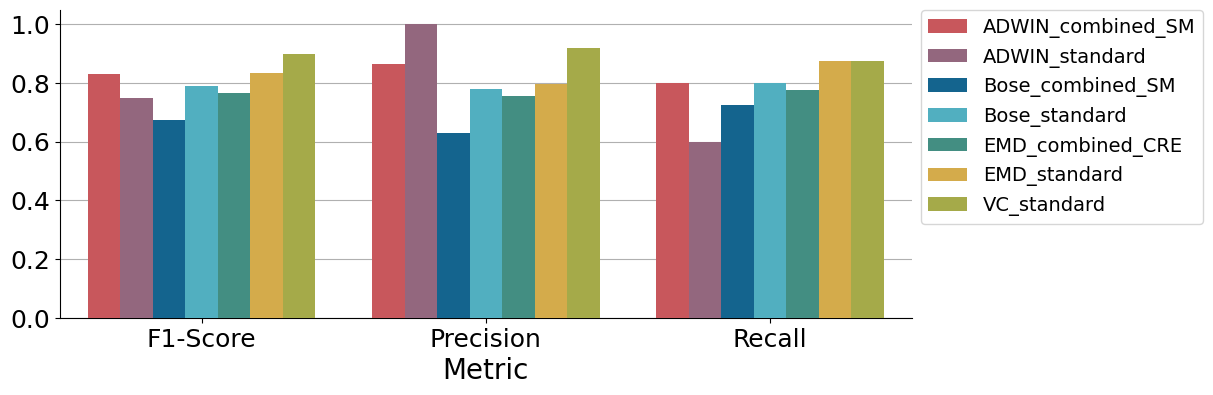

In [23]:

accuracy_plot_df = pd.DataFrame(
    [
        {
            "Algorithm": name,
            "Metric": "F1-Score",
            "Value": computed_accuracy_dicts[name][accuracy_best_param[name]]
        }
        for name in computed_accuracy_dicts.keys()
    ] + [
        {
            "Algorithm": name,
            "Metric": "Precision",
            "Value": computed_precision_dicts[name][accuracy_best_param[name]]
        }
        for name in computed_accuracy_dicts.keys()
    ] + [
        {
            "Algorithm": name,
            "Metric": "Recall",
            "Value": computed_recall_dicts[name][accuracy_best_param[name]]
        }
        for name in computed_accuracy_dicts.keys()
    ]
)

palette=None #{"Precision": "#573deb", "F1-Score": "#ff0076", "Recall": "#ffa600"}
palette = sns.color_palette(colors)
plt.grid(zorder=0)
ax = sns.barplot(x="Metric", y="Value", data=accuracy_plot_df, hue="Algorithm", palette=palette, hue_order=ALPHA_SORT_NAMES,zorder =5)

ax.figure.set_size_inches(11, 4)
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)
ax.tick_params(labelsize=18)
ax.set_xlabel(ax.get_xlabel(), size = 20)
ax.set_ylabel("", size = 20)
#ax.get_yaxis().set_visible(False)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', borderaxespad=0,prop={'size': 14})

if not os.path.exists(f"{OUT_PATH}/Accuracy{LAG_WINDOW}"):
    os.makedirs(f"{OUT_PATH}/Accuracy{LAG_WINDOW}")
plt.savefig(f"{OUT_PATH}/Accuracy{LAG_WINDOW}/accuracy_c.pdf", bbox_inches="tight", format="pdf")
plt.show()

### Plot as Points

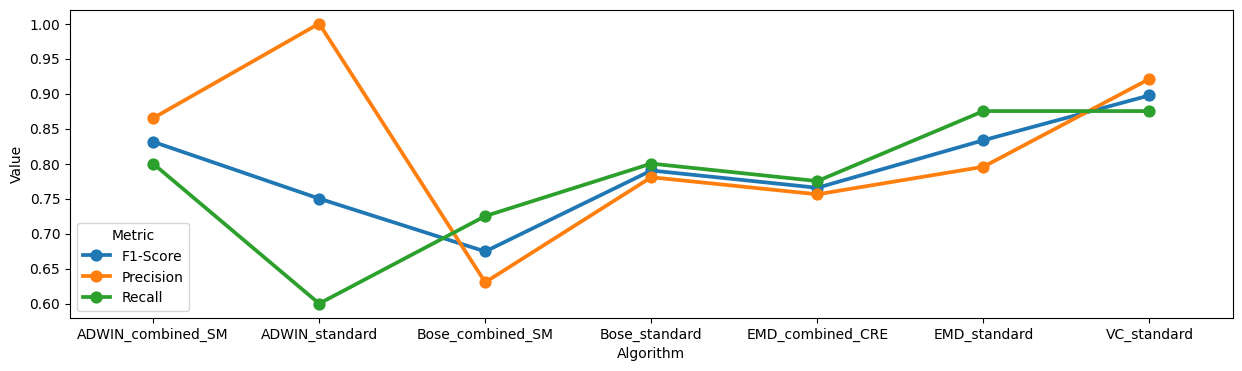

In [24]:
ax = sns.pointplot(
    x="Algorithm",
    y="Value",
    data=accuracy_plot_df,
    hue="Metric",
    order=ALPHA_SORT_NAMES,
    join=True,
)
ax.figure.set_size_inches(15, 4)
plt.show()

## Latency
- Using best parameter setting
- Same logs as above

In [25]:
from statistics import mean

def calcLatencies(df, param_names, lag_window):
    latencies = dict()
    for parameters, group in df.groupby(by=param_names):
        lags = []
        for index, row in group.iterrows():
            actual_cp = row["Actual Changepoints for Log"]
            detected_cp = row["Detected Changepoints"]
            assignments = evaluation.assign_changepoints(detected_cp, actual_cp, lag_window)
            for d, a in assignments:
                lags.append(abs(d-a))
        latencies[parameters] = lags
    return latencies

def calculate_latency(dataframe, lag_window, min_support=1, verbose=True):
    latencies = dict() # Dict holding the best achieved latency per approach
    scaled_latency_dicts = dict() # Dict holding the scaled mean latency per approach per parameter setting
    computed_latency_dicts = dict() # Dict holding the raw list of detection lags per approach per parameter setting
    best_params_latency = dict() # Dict holding the best parameter setting per approach (the one that achieves the best latency)
    for name, a_df in dataframe.groupby(by="Algorithm"):
        result = calcLatencies(a_df, used_parameters[name], LAG_WINDOW)
        computed_latency_dicts[name] = result
        latency_scaled_dict = {
            param: 1-(mean(result[param])/LAG_WINDOW) if len(result[param]) >= min_support else np.NaN
            for param in result.keys()
        }
        scaled_latency_dicts[name] = latency_scaled_dict
        best_param = max(latency_scaled_dict,  key=lambda x: latency_scaled_dict[x] if not np.isnan(latency_scaled_dict[x]) else -1)

        best_params_latency[name] = best_param
        latencies[name] = latency_scaled_dict[best_param]

        if verbose:
            print(f"{name}: {(1-latencies[name])*LAG_WINDOW} Traces; Score: {latencies[name]}")
    return (latencies, scaled_latency_dicts, computed_latency_dicts, best_params_latency)

latencies, scaled_latency_dicts, computed_latency_dicts, best_params_latency = calculate_latency(df_noiseless, LAG_WINDOW, min_support=MIN_SUPPORT, verbose=False)

pd.DataFrame([{'Algorithm': name, 'Lag (Traces)': (1-latencies[name])*LAG_WINDOW, 'Lag (Score)': latencies[name]} for name in latencies.keys()]).sort_values(by="Algorithm", ascending=True)

,Algorithm,Lag (Traces),Lag (Score)
0,ADWIN_combined_SM,74.218750,0.628906
1,ADWIN_standard,76.833333,0.615833
2,Bose_combined_SM,57.896552,0.710517
3,Bose_standard,53.500000,0.732500
4,EMD_combined_CRE,80.032258,0.599839
5,EMD_standard,51.857143,0.740714
6,VC_standard,71.142857,0.644286


#### Plot Latency
- Plotting the observed average latency along with the corresponding standard deviation for the found best parameter setting

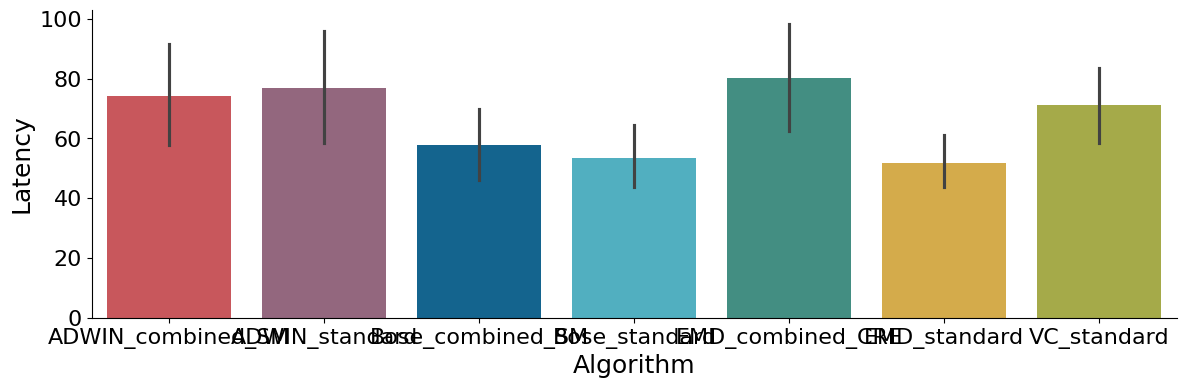

In [26]:
latency_plot_df = pd.DataFrame([
    {
        "Algorithm": name,
        "Unscaled Latency": latency
    }
    for name in computed_latency_dicts.keys()
    for latency in computed_latency_dicts[name][best_params_latency[name]]
])

ax = plt.subplots(figsize=(17, 4))

# Order by latency, ascending (best is left)
# order = [name for name, _ in sorted(latencies.items(), key=lambda x: x[1] if not np.isnan(x[1]) else 0, reverse=True)]
# print(order)
ax = sns.barplot(x="Algorithm", y="Unscaled Latency", data=latency_plot_df,palette= palette, order=ALPHA_SORT_NAMES)
plt.ylabel("Latency")# [Traces]")
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)
ax.tick_params(labelsize=16)
ax.set_xlabel(ax.get_xlabel(), size = 18)
ax.set_ylabel(ax.get_ylabel(), size = 18)
ax.figure.set_size_inches(14, 4)

if not os.path.exists(f"{OUT_PATH}/Latency{LAG_WINDOW}"):
    os.makedirs(f"{OUT_PATH}/Latency{LAG_WINDOW}")
plt.savefig(f"{OUT_PATH}/Latency{LAG_WINDOW}/latency.pdf", bbox_inches="tight", format="pdf")
plt.show()


## Versatility

#### Preprocessing

In [27]:
# Only use Ceravolo and Ostovar Logs because these are the only ones that have different change patterns.
# (Theoretically we could also drop all rows containing a nan in the change pattern column? This would be more general)
df_v = df_noiseless[df_noiseless["Log Source"].isin(["Ceravolo", "Ostovar"])].copy(deep=True)

#### Calculation
- Recall of all logs of the same pattern, "concatenated", i.e., accumulate TP and FP first
  - &rArr; Ignoring duplicate detections has no effect on the recall as $\mathit{recall}=\frac{tps}{positives}$
- Divide this by the number of change patterns

In [28]:
def calc_versatility(dataframe, lag_window, verbose=True):

    versatility_recall_dicts = dict() # Map approach to a dictionary mapping param setting to mean recall over all change patterns
    versatilities = dict() # Map approach to versatility score
    best_params_versatility = dict() # Map approach to best param setting

    for name, group in dataframe.groupby(by="Algorithm"):
        recalls_of_this_approach = dict()
        for params, params_group in group.groupby(by=used_parameters[name]):
            recalls = dict()
            for change_pattern, cp_group in params_group.groupby(by="Change Pattern"):
                TPS = 0
                POSITIVES = 0
                # TP / TP+FN = TP / POSTIVES = Recall
                for index, row in cp_group.iterrows():
                    detected_changepoints = row["Detected Changepoints"]
                    actual_changepoints = row["Actual Changepoints for Log"]

                    tp, _ = evaluation.getTP_FP(detected_changepoints, actual_changepoints, lag_window, count_duplicate_detections=COUNT_DUPLICATE_DETECTIONS)

                    TPS += tp
                    POSITIVES += len(actual_changepoints)

                # Recall of this algorithm for this change pattern:
                recall = TPS / POSITIVES if POSITIVES != 0 else np.NaN # Only the case if there are no actual changepoints, which should not be the case
                recalls[change_pattern] = recall
            recalls_of_this_approach[params] = recalls
        versatility_recall_dicts[name] = recalls_of_this_approach
        best_param = max(recalls_of_this_approach, key=lambda x: np.nanmean(list(recalls_of_this_approach[x].values()))) # .values() gives us all the recalls for all change patterns on this param setting
        best_params_versatility[name] = best_param
        versatilities[name] = np.nanmean(list(
            recalls_of_this_approach[best_param].values()
        ))
        
        if verbose:
            print(f"{name}: {versatilities[name]}")
        
    return versatilities, versatility_recall_dicts, best_params_versatility

versatilities, versatility_recall_dicts, best_params_versatility = calc_versatility(df_v, LAG_WINDOW, verbose=False)

pd.DataFrame([{'Algorithm': name, 'Versatility': versatilities[name]} for name in versatilities.keys()]).sort_values(by="Algorithm", ascending=True)


,Algorithm,Versatility
0,ADWIN_combined_SM,0.781250
1,ADWIN_standard,0.572917
2,Bose_combined_SM,0.666667
3,Bose_standard,0.770833
4,EMD_combined_CRE,0.750000
5,EMD_standard,0.875000
6,VC_standard,0.916667


#### Plot
- Barplot with "bar" for each change pattern and approach

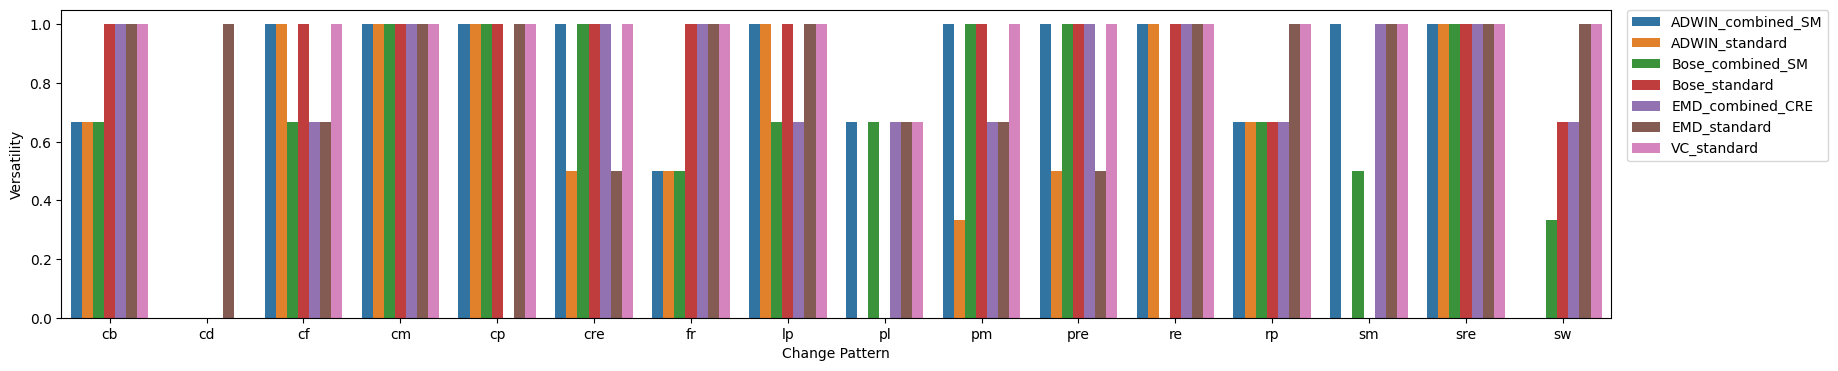

In [29]:
df_vers_plot = pd.DataFrame([
    {
        "Algorithm": name,
        "Change Pattern": cp,
        "Versatility": versatility_recall_dicts[name][best_params_versatility[name]][cp]
    }
    for name in versatility_recall_dicts.keys()
    for cp in versatility_recall_dicts[name][best_params_versatility[name]].keys()
])
df_vers_plot.pivot(index="Algorithm", columns="Change Pattern", values="Versatility").to_csv("versatility_by_approach.csv")

fig,ax = plt.subplots(figsize=(20, 4))
sns.barplot(x="Change Pattern", y="Versatility", data=df_vers_plot, hue="Algorithm", ax=ax, hue_order=ALPHA_SORT_NAMES)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', borderaxespad=0)

if not os.path.exists(f"{OUT_PATH}/Versatility{LAG_WINDOW}"):
    os.makedirs(f"{OUT_PATH}/Versatility{LAG_WINDOW}")
plt.savefig(f"{OUT_PATH}/Versatility{LAG_WINDOW}/versatility.pdf", bbox_inches="tight", format="pdf")
plt.show()

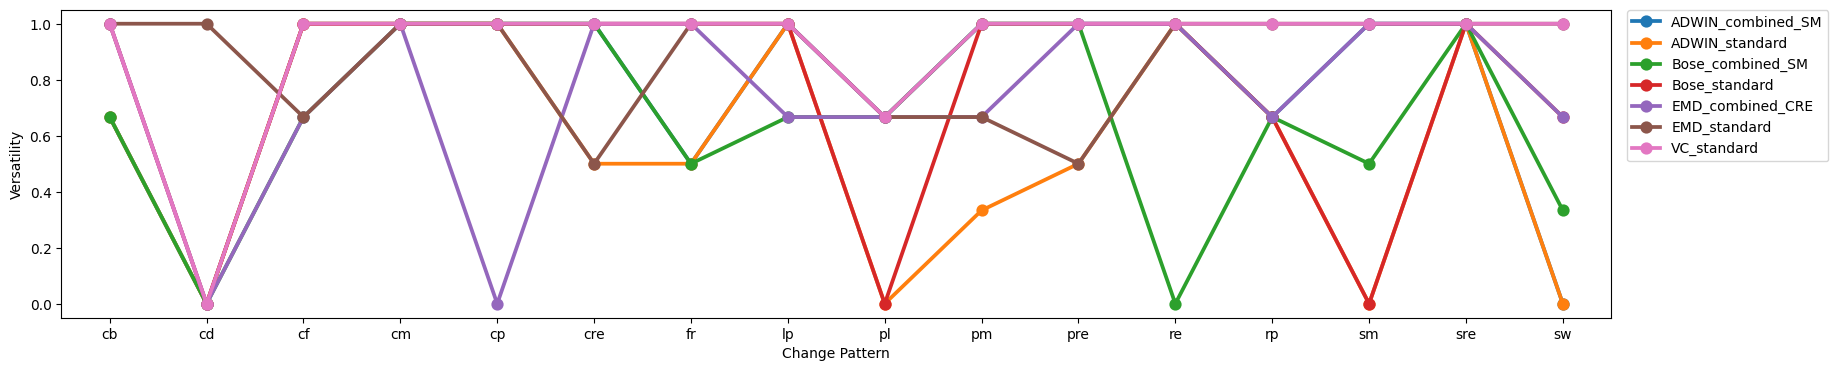

In [30]:
change_patterns = sorted(list(df_vers_plot["Change Pattern"].unique()))
ax = sns.pointplot(
    x="Change Pattern",
    y="Versatility",
    data=df_vers_plot,
    hue="Algorithm",
    hue_order=ALPHA_SORT_NAMES,
    order=change_patterns
)
ax.figure.set_size_inches(20,4)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', borderaxespad=0)
plt.show()

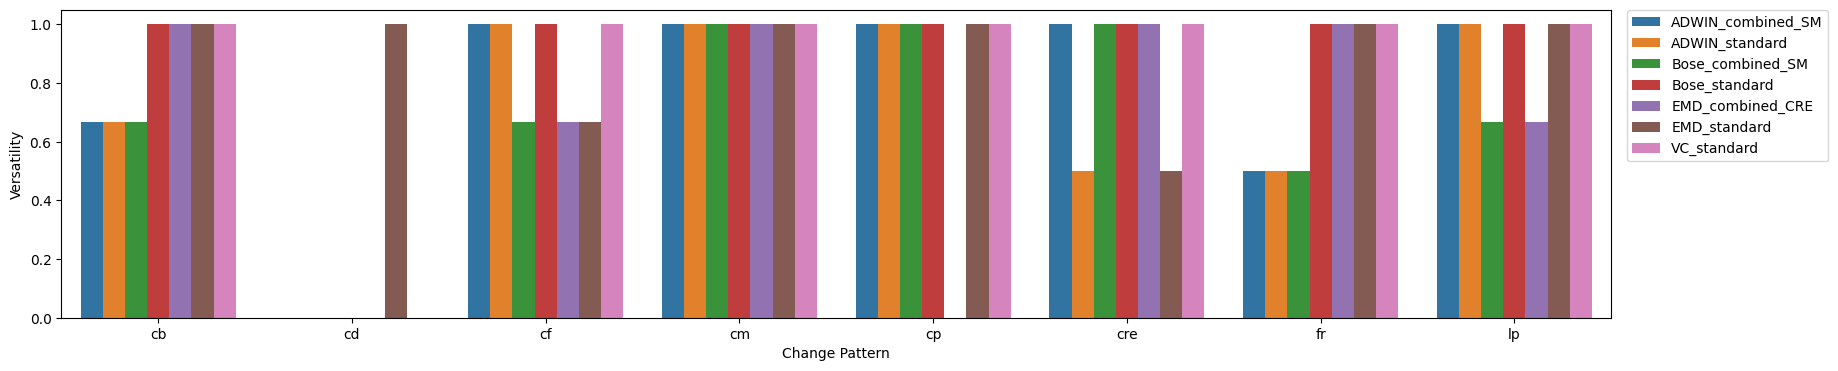

In [31]:
# Plot again, but split in half
first_half = change_patterns[:len(change_patterns)//2]
second_half = change_patterns[len(change_patterns)//2:]
fig,ax = plt.subplots(figsize=(20, 4))
sns.barplot(x="Change Pattern", y="Versatility", data=df_vers_plot[df_vers_plot["Change Pattern"].isin(first_half)], hue="Algorithm", order=first_half, ax=ax, hue_order=ALPHA_SORT_NAMES)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', borderaxespad=0)

plt.savefig(f"{OUT_PATH}/Versatility{LAG_WINDOW}/versatility_split_1.pdf", bbox_inches="tight", format="pdf")
plt.show()

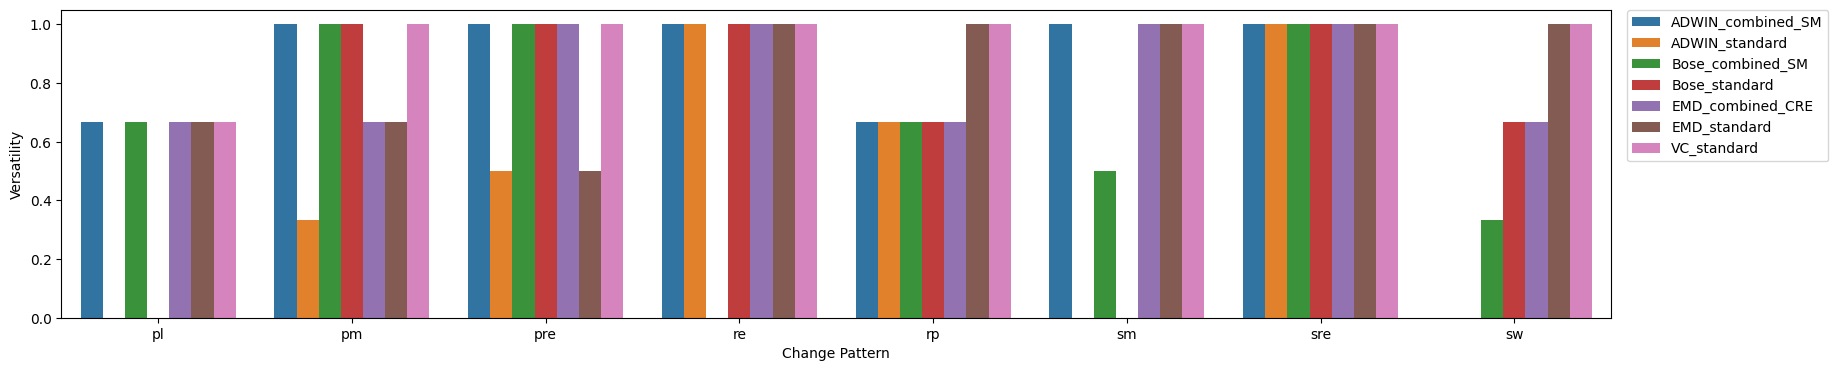

In [32]:
fig2,ax2 = plt.subplots(figsize=(20, 4))
sns.barplot(x="Change Pattern", y="Versatility", data=df_vers_plot[df_vers_plot["Change Pattern"].isin(second_half)], hue="Algorithm", order=second_half, ax=ax2, hue_order=ALPHA_SORT_NAMES)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', borderaxespad=0)
plt.savefig(f"{OUT_PATH}/Versatility{LAG_WINDOW}/versatility_split_2.pdf", bbox_inches="tight", format="pdf")
plt.show()

#### Plot as Radar Chart

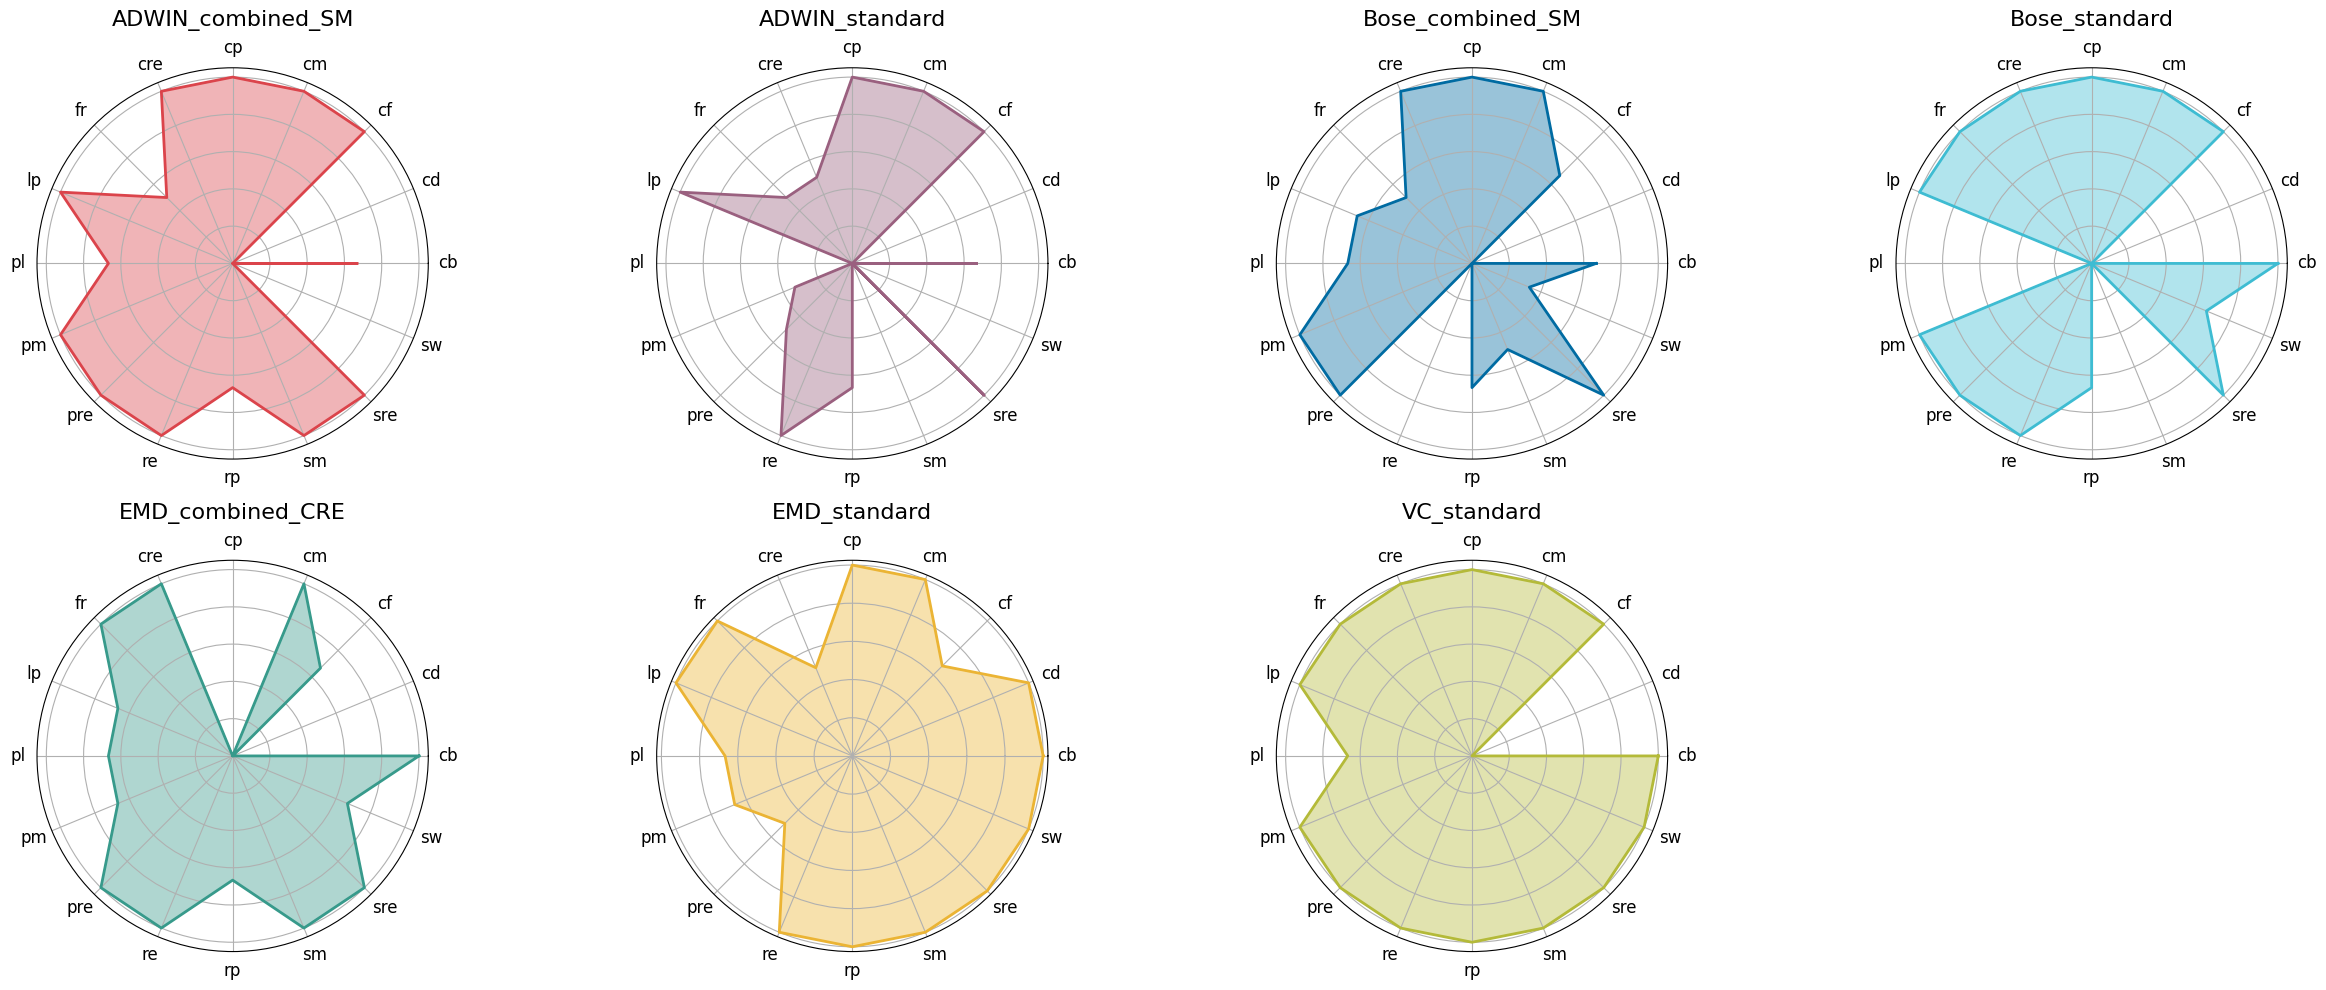

Exception ignored in: <function ResourceTracker.__del__ at 0x7c086a12a840>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/multiprocessing/resource_tracker.py", line 77, in __del__
  File "/usr/local/lib/python3.12/multiprocessing/resource_tracker.py", line 86, in _stop
  File "/usr/local/lib/python3.12/multiprocessing/resource_tracker.py", line 111, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x7896bf522840>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/multiprocessing/resource_tracker.py", line 77, in __del__
  File "/usr/local/lib/python3.12/multiprocessing/resource_tracker.py", line 86, in _stop
  File "/usr/local/lib/python3.12/multiprocessing/resource_tracker.py", line 111, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x7c17af63a840>
Traceback (most recent call last):
  File "/usr

In [52]:
import os
import warnings
import numpy as np
import matplotlib.pyplot as plt

plotly_default_colors = colors
fill_colors = {
    name: plotly_default_colors[idx]
    for idx,name in enumerate(df_vers_plot["Algorithm"].unique())
}


with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)
    
    base_path = f"{OUT_PATH}/Versatility{LAG_WINDOW}/Radar_Charts"
    os.makedirs(base_path, exist_ok=True)

    # All unique categories (consistent order)
    categories = df_vers_plot["Change Pattern"].unique().tolist()
    N = len(categories)
    angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
    angles += angles[:1]  # close the circle

    fig, axes = plt.subplots(2, 4, subplot_kw=dict(polar=True), figsize=(25, 10))
    axes = axes.flatten()

    for ax, (alg, dataframe) in zip(axes, df_vers_plot.groupby("Algorithm")):
        # Align dataframe with full category list
        df_alg = dataframe.set_index("Change Pattern").reindex(categories)
        values = df_alg["Versatility"].fillna(0).tolist()
        values += values[:1]  # close the shape

        color = fill_colors.get(alg, "#1f77b4")
        ax.plot(angles, values, color=color, linewidth=2)
        ax.fill(angles, values, color=color, alpha=0.4)

        # Label formatting
        ax.set_xticks(angles[:-1])
        ax.set_xticklabels(categories, fontsize=12)
        ax.set_yticklabels([])
        ax.set_title(alg, va='bottom', fontsize=16)

    # Hide unused cells if there are fewer than 10 algorithms
    for ax in axes[df_vers_plot["Algorithm"].nunique():]:
        ax.set_visible(False)

    plt.tight_layout()
    output_path = f"versatility_by_approach_plot.pdf"
    plt.savefig(output_path, format="pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)


## Scalability
- Mean Duration
- Across ***all*** logs this time!

In [34]:
scalabilities = dict()
for name, a_df in df.groupby("Algorithm"):
    result = a_df["Duration (Seconds)"].mean()
    result_str = datetime.strftime(datetime.utcfromtimestamp(result), '%H:%M:%S')
    scalabilities[name] = {"avg_seconds": result, "str": result_str}

pd.DataFrame([{'Algorithm': name, 'Scalability': scalabilities[name]["str"], 'Average Seconds': scalabilities[name]['avg_seconds']} for name in scalabilities.keys()]).sort_values(by="Algorithm", ascending=True)

,Algorithm,Scalability,Average Seconds
0,ADWIN_combined_SM,00:01:15,75.335537
1,ADWIN_standard,00:01:15,75.548695
2,Bose_combined_SM,00:17:09,1029.463679
3,Bose_standard,00:17:09,1029.381430
4,EMD_combined_CRE,00:03:56,236.241042
5,EMD_standard,00:03:49,229.417109
6,VC_standard,00:00:02,2.727693


#### Plot Boxplot of Mean Absolute Duration

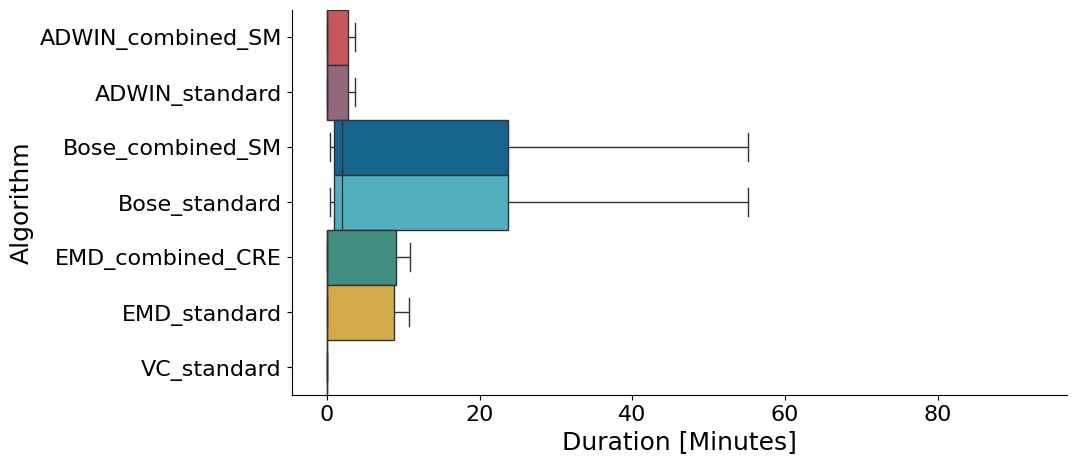

In [35]:
scalability_plot_df = pd.DataFrame([
    {
        "Algorithm": name,
        "Duration": duration / 60
    }
    for name, a_df in dfs
    for duration in a_df["Duration (Seconds)"].tolist()
])

fig, ax = plt.subplots(figsize=(10, 5))
ax.set_xlabel("Duration [Minutes]")

sorted_names = list(scalabilities.items())
sorted_names.sort(key=lambda x: x[1]["avg_seconds"])

ax = sns.boxplot(
    data=scalability_plot_df,
    order=ALPHA_SORT_NAMES,#[name for name, _ in sorted_names] if False else None, # Disable sorting for now, maybe this means that the order is the same in every plot
    x="Duration",
    y="Algorithm",
    palette = palette,
    width=1,
    ax=ax,
    fliersize=0
)
#ax.figure.set_size_inches(14, 4)
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)
ax.tick_params(labelsize=16)
ax.set_xlabel(ax.get_xlabel(), size = 18)
ax.set_ylabel(ax.get_ylabel(), size = 18)
plt.xlabel("Duration [Minutes]")

if not os.path.exists(f"{OUT_PATH}/Scalability{LAG_WINDOW}"):
    os.makedirs(f"{OUT_PATH}/Scalability{LAG_WINDOW}")
plt.savefig(f"{OUT_PATH}/Scalability{LAG_WINDOW}/scalability.pdf", bbox_inches="tight", format="pdf")
plt.show()

#### Plot as Barplot as well

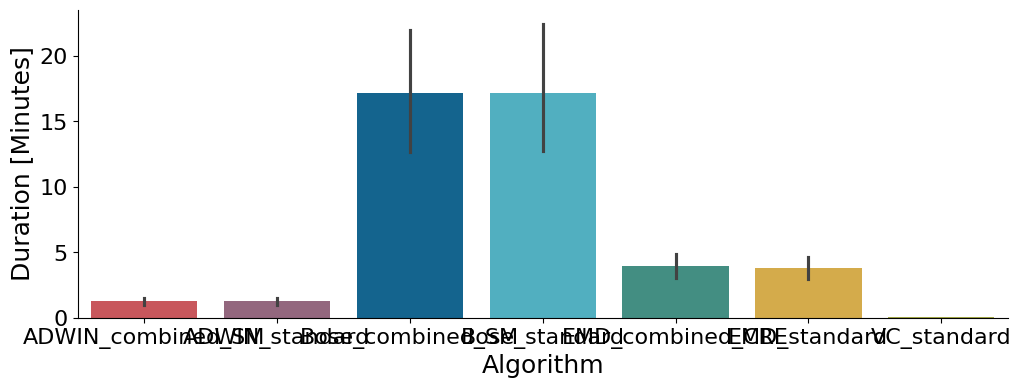

In [36]:
scalability_barplot_df = pd.DataFrame([
    {
        "Algorithm": name,
        "Duration": duration / 60
    }
    for name, a_df in dfs
    for duration in a_df["Duration (Seconds)"].tolist()
])

ax = plt.subplots(figsize=(17, 4))

# Order by latency, ascending (best is left)
# order = [name for name, _ in sorted(latencies.items(), key=lambda x: x[1] if not np.isnan(x[1]) else 0, reverse=True)]
# print(order)

ax = sns.barplot(x="Algorithm", y="Duration", data=scalability_barplot_df,palette = palette, order=ALPHA_SORT_NAMES)
ax.figure.set_size_inches(12, 4)
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)
ax.tick_params(labelsize=16)
ax.set_xlabel(ax.get_xlabel(), size = 18)
ax.set_ylabel(ax.get_ylabel(), size = 18)
plt.ylabel("Duration [Minutes]")
plt.savefig(f"{OUT_PATH}/Scalability{LAG_WINDOW}/scalability_barplot.pdf", bbox_inches="tight", format="pdf")
plt.show()

## Seconds per Case/Event

In [37]:
df_seconds = df.copy()

# Build the log key as a string to match dictionary keys
log_keys = df_seconds.apply(
    lambda x: str(Path(EvaluationLogs_path, x["Log Source"], x["Log"] + ".xes.gz")),
    axis=1
)

# Map lengths from the dictionaries
df_seconds["Log Length (Cases)"] = log_keys.map(loglengths)
df_seconds["Log Length (Events)"] = log_keys.map(loglengths_events)

# Compute seconds per case / per event per algorithm
seconds_per_case = {}
seconds_per_event = {}

for name, group in df_seconds.groupby("Algorithm"):
    total_seconds = group["Duration (Seconds)"].sum()
    total_cases = group["Log Length (Cases)"].sum()
    total_events = group["Log Length (Events)"].sum()

    seconds_per_case[name] = total_seconds / total_cases
    seconds_per_event[name] = total_seconds / total_events

# Convert results to DataFrame
result_df = pd.DataFrame([
    {
        'Algorithm': name,
        'Seconds per Case': seconds_per_case[name],
        'Seconds per Event': seconds_per_event[name]
    } 
    for name in seconds_per_case.keys()
]).sort_values(by="Algorithm", ascending=True)

result_df


,Algorithm,Seconds per Case,Seconds per Event
0,ADWIN_combined_SM,0.039201,0.001504
1,ADWIN_standard,0.039312,0.001508
2,Bose_combined_SM,0.535680,0.020548
3,Bose_standard,0.535637,0.020547
4,EMD_combined_CRE,0.122928,0.004715
5,EMD_standard,0.119377,0.004579
6,VC_standard,0.001419,0.000054


In [38]:
df_seconds["Milliseconds per Event"] = df_seconds.apply(lambda x: (x["Duration (Seconds)"]*1000) / x["Log Length (Events)"], axis=1)
df_seconds[["Duration (Seconds)", "Log Length (Events)", "Milliseconds per Event"]].head()

,Duration (Seconds),Log Length (Events),Milliseconds per Event
0,4.419267,10223,0.432287
1,4.713537,10365,0.454755
2,3.322847,9967,0.333385
3,4.135546,10334,0.400188
4,4.257473,9699,0.438960


### Plot Boxplot and Barplot of milliseconds per event

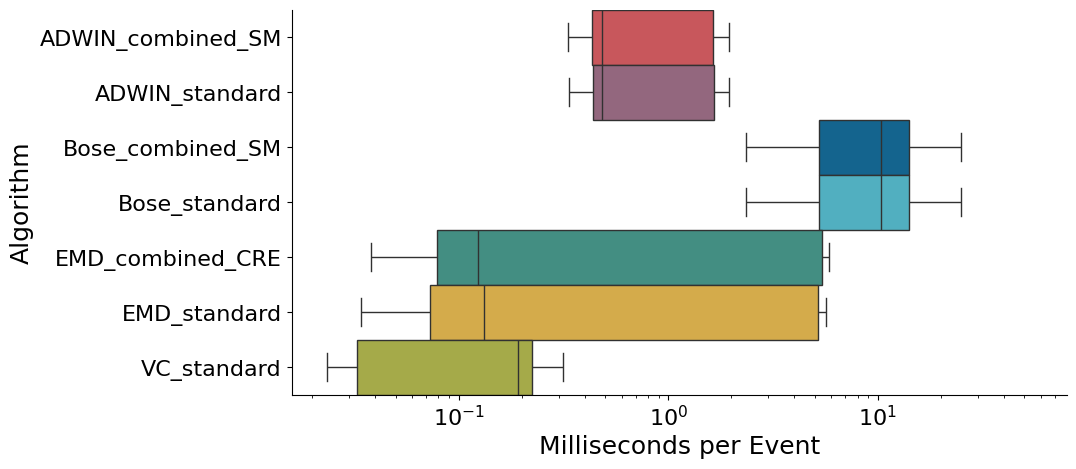

In [39]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.set_xlabel("Milliseconds per Event")


ax = sns.boxplot(
    data=df_seconds,
    order=ALPHA_SORT_NAMES,
    x="Milliseconds per Event",
    y="Algorithm",
    palette = palette,
    width=1,
    ax=ax,
    fliersize=0

)

ax.set_xscale("log")

ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)
ax.tick_params(labelsize=16)
ax.set_xlabel(ax.get_xlabel(), size = 18)
ax.set_ylabel(ax.get_ylabel(), size = 18)
plt.xlabel("Milliseconds per Event")

if not os.path.exists(f"{OUT_PATH}/Scalability{LAG_WINDOW}"):
    os.makedirs(f"{OUT_PATH}/Scalability{LAG_WINDOW}")
plt.savefig(f"{OUT_PATH}/Scalability{LAG_WINDOW}/scalability_mseconds_per_event.pdf", bbox_inches="tight", format="pdf")
plt.show()
plt.close(fig)

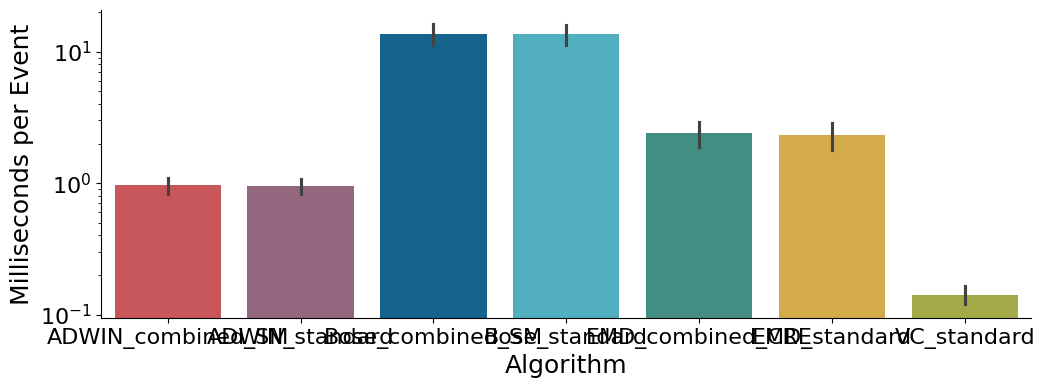

In [40]:
ax = plt.subplots(figsize=(17, 4))

ax = sns.barplot(x="Algorithm", y="Milliseconds per Event", data=df_seconds, palette = palette, order=ALPHA_SORT_NAMES)
ax.figure.set_size_inches(12, 4)
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)
ax.tick_params(labelsize=16)
ax.set_xlabel(ax.get_xlabel(), size = 18)
ax.set_ylabel(ax.get_ylabel(), size = 18)
ax.set_yscale("log")
plt.ylabel("Milliseconds per Event")

if not os.path.exists(f"{OUT_PATH}/Scalability{LAG_WINDOW}"):
    os.makedirs(f"{OUT_PATH}/Scalability{LAG_WINDOW}")
plt.savefig(f"{OUT_PATH}/Scalability{LAG_WINDOW}/scalability_mseconds_per_event_barplot.pdf", bbox_inches="tight", format="pdf")
plt.show()

## Parameter Sensitivity
- For each Parameter setting, harmonic mean of *accuracy*, *latency*, and *versatility*
  - &rarr; Visualize the variance, etc., with a boxplot
- Only noiseless logs again

In [41]:
versatility_score_per_param = {
    name: {
        params: np.nanmean(list(versatility_recall_dicts[name][params].values()))
        for params in versatility_recall_dicts[name].keys()
    }
    for name in versatility_recall_dicts.keys()
}


sensitivities = dict()
for name in df["Algorithm"].unique():
    _sensitivities = dict()
    acc = computed_accuracy_dicts[name]
    lat = scaled_latency_dicts[name]
    vers = versatility_score_per_param[name]
    for param_choice in acc.keys():
        sensitivity = harmonic_mean([acc[param_choice], vers[param_choice], lat[param_choice]])
        _sensitivities[param_choice] = sensitivity
    sensitivities[name] = _sensitivities


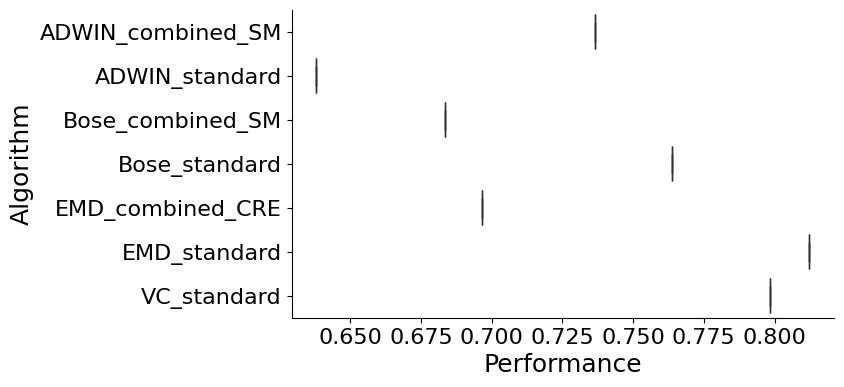

In [42]:
sens_df = pd.DataFrame([
    {
        "Parameters": param,
        "Algorithm": name,
        "Sensitivity Score": sens
    }
    for name, sens_dict in sensitivities.items()
    for param, sens in sens_dict.items()
])
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 5))
ax = sns.boxplot(
    data=sens_df,
    x="Sensitivity Score",
    y="Algorithm",
    palette = palette,
    ax=ax,
    fliersize=0,
    order=ALPHA_SORT_NAMES
)
ax.figure.set_size_inches(7, 4)
ax.spines.right.set_visible(False)
ax.spines.top.set_visible(False)
ax.tick_params(labelsize=16)
ax.set_xlabel("Performance", size = 18)
ax.set_ylabel(ax.get_ylabel(), size = 18)

if not os.path.exists(f"{OUT_PATH}/Parameter_Sensitivity{LAG_WINDOW}"):
    os.makedirs(f"{OUT_PATH}/Parameter_Sensitivity{LAG_WINDOW}")
plt.savefig(f"{OUT_PATH}/Parameter_Sensitivity{LAG_WINDOW}/param_sensitivity.pdf", bbox_inches="tight", format="pdf")
plt.show()

In [43]:
# Inter Quartile Range
sensitivity_iqrs = dict()
for name, sens in sensitivities.items():
    _iqr = iqr(list(sens.values()), nan_policy="omit")
    sensitivity_iqrs[name] = _iqr

pd.DataFrame([{'Algorithm': name, 'Inner-Quartile Range': sensitivity_iqrs[name]} for name in sensitivity_iqrs.keys()]).sort_values(by="Algorithm", ascending=True)

,Algorithm,Inner-Quartile Range
0,ADWIN_combined_SM,0.0
1,ADWIN_standard,0.0
2,Bose_combined_SM,0.0
3,Bose_standard,0.0
4,EMD_combined_CRE,0.0
5,EMD_standard,0.0
6,VC_standard,0.0


## Robustness

### Preprocessing

In [44]:
# # Only use the Ceravolo and Ostovar Logs as Bose has only 1 log, i.e., no noise levels
df_robust = df[df["Log Source"].isin(["Ceravolo", "Ostovar"])].copy(deep=True)
df_robust[['Algorithm', 'Log Source', 'Log', 'Change Pattern', 'Noise Level']]

,Algorithm,Log Source,Log,Change Pattern,Noise Level
0,ADWIN_combined_SM,Ceravolo,sudden_trace_noise10_1000_cd,cd,10
1,ADWIN_combined_SM,Ceravolo,sudden_trace_noise10_1000_pl,pl,10
2,ADWIN_combined_SM,Ceravolo,sudden_trace_noise15_1000_pm,pm,15
3,ADWIN_combined_SM,Ceravolo,sudden_trace_noise15_1000_cf,cf,15
4,ADWIN_combined_SM,Ceravolo,sudden_trace_noise20_1000_cd,cd,20
...,...,...,...,...,...
678,VC_standard,Ostovar,Atomic_ParallelRemoval_output_ParallelRemoval_2,pre,2
679,VC_standard,Ostovar,Atomic_ParallelMove_output_ParallelMove_5,pm,5
680,VC_standard,Ostovar,Atomic_ConditionalToSequence_output_Conditiona...,cf,5
681,VC_standard,Ostovar,Atomic_ParallelToSequence_output_ParallelToSeq...,pl,0


### Calculate Harmonic Means

In [45]:
from joblib import Parallel, delayed

def compute_robustness_for_noise(noise_level, noise_df, lag_window):
    """Compute robustness for a single noise level."""
    accuracies, _, _, _, _ = calculate_accuracy_metric_df(noise_df, lag_window, verbose=False)
    latencies, _, _, _ = calculate_latency(noise_df, lag_window, min_support=MIN_SUPPORT, verbose=False)
    versatilities, _, _ = calc_versatility(noise_df, lag_window, verbose=False)

    # Ensure same keys
    assert accuracies.keys() == latencies.keys() == versatilities.keys()

    robustness = {
        approach: harmonic_mean([accuracies[approach], latencies[approach], versatilities[approach]])
        for approach in accuracies.keys()
    }

    return noise_level, robustness


def calc_robustnesses_parallel(dataframe, lag_window, n_jobs=-1):
    noise_groups = list(dataframe.groupby("Noise Level"))

    results = Parallel(n_jobs=n_jobs)(
        delayed(compute_robustness_for_noise)(noise_level, noise_df, lag_window)
        for noise_level, noise_df in noise_groups
    )

    # Combine results into dictionary
    robustnesses = dict(results)
    return robustnesses

means_ceravolo = calc_robustnesses_parallel(df_robust[df_robust["Log Source"] == "Ceravolo"], LAG_WINDOW)
means_ostovar = calc_robustnesses_parallel(df_robust[df_robust["Log Source"] == "Ostovar"], LAG_WINDOW)


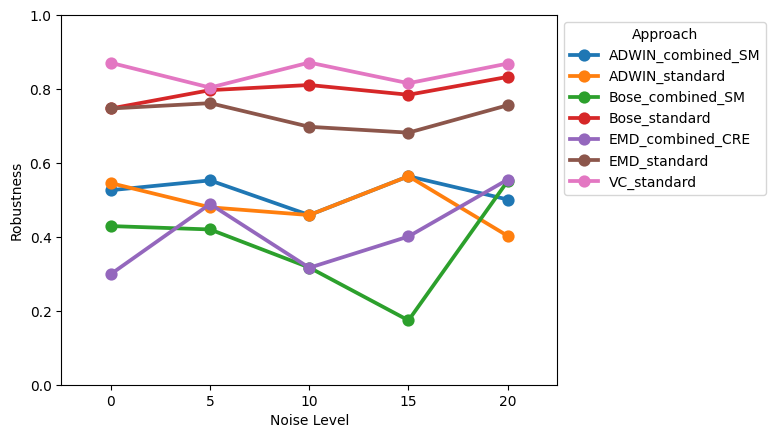

In [46]:
plot_df_robust = pd.DataFrame(
    ([
        {
            "Log Set": "Ostovar",
            "Approach": name,
            "Noise Level": int(noise_level),
            "Robustness": robustness
        }
        for noise_level, robust_dict  in means_ostovar.items()
        for name, robustness in robust_dict.items()
    ] + [
        {
            "Log Set": "Ceravolo",
            "Approach": name,
            "Noise Level": int(noise_level),
            "Robustness": robustness
        }
        for noise_level, robust_dict  in means_ceravolo.items()
        for name, robustness in robust_dict.items()
    ])
)

ax = sns.pointplot(x="Noise Level", y="Robustness", hue="Approach", data=plot_df_robust[plot_df_robust["Log Set"] == "Ceravolo"], errorbar=None)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
ax.set_ylim(0,1)
plt.show()

### Compute AUC

In [47]:
# Calculate AUC Thing
def convert_harm_mean_to_auc(means, div_zero_default=0):
    ## Conventions:
        # If any harmonic mean is nan, then set it to 0 instead


    def _convert_nan_to_zero(x):
        if np.isnan(x):
            x = 0
        return x

    # means maps {noise_level: {approach: robustness}}
    # reformat to {approach: [(noise_level, robustness)]}
    means = {
        approach: [
            (int(noise_level), _convert_nan_to_zero(means[noise_level][approach]))
            for noise_level in means.keys()
        ]
        for approach in means["0"].keys()
    }

    robustnesses = dict()
    for approach in means.keys():
        points = sorted(means[approach], key=lambda x: x[0])

        # Initial Robustness - Use to model "Ideal Robustness"
        initial_robustness = points[0][1] # Robustness for lowest (0%) noise
        ideal_auc = initial_robustness * (points[-1][0] - points[0][0]) # AUC if it was always exactly as good as for the lowest noise level. If performance increases with higher noise, the achieved AUC might be larger than ideal AUC
        prev_noise, prev_robust = points[0]
        auc = 0
        for noise, robust in points[1:]:
            delta_noise = noise-prev_noise
            sum_robust = prev_robust+robust

            # "ROC Index"
            area = (delta_noise * sum_robust) / 2# Area under curve for this segment
            auc += area

            prev_noise = noise
            prev_robust = robust

        if ideal_auc != 0:
            robustnesses[approach] = auc / ideal_auc
        else:
            robustnesses[approach] = div_zero_default
    return robustnesses

robustness_ceravolo = convert_harm_mean_to_auc(means_ceravolo)
robustness_ostovar = convert_harm_mean_to_auc(means_ostovar)

### Calculate Final Robustness Score by Calculating mean of Ceravolo and Ostovar

In [48]:
assert robustness_ceravolo.keys() == robustness_ostovar.keys() # This should always be the case..
robustnesses = {
    name: (robustness_ceravolo[name] + robustness_ostovar[name]) / 2
    for name in robustness_ceravolo.keys()
}

pd.DataFrame([{'Algorithm': name, 'Robustness': robustnesses[name]} for name in robustnesses.keys()]).sort_values(by="Algorithm", ascending=True)


,Algorithm,Robustness
0,ADWIN_combined_SM,0.890441
1,ADWIN_standard,0.821242
2,Bose_combined_SM,0.927038
3,Bose_standard,1.024450
4,EMD_combined_CRE,1.197028
5,EMD_standard,0.999219
6,VC_standard,0.985246


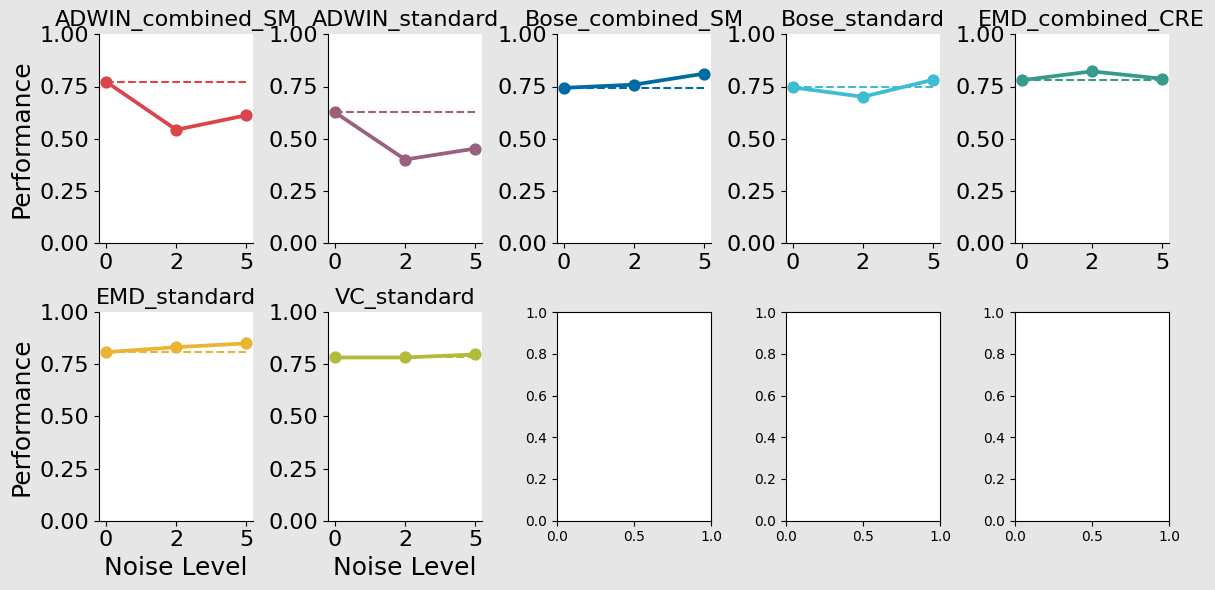

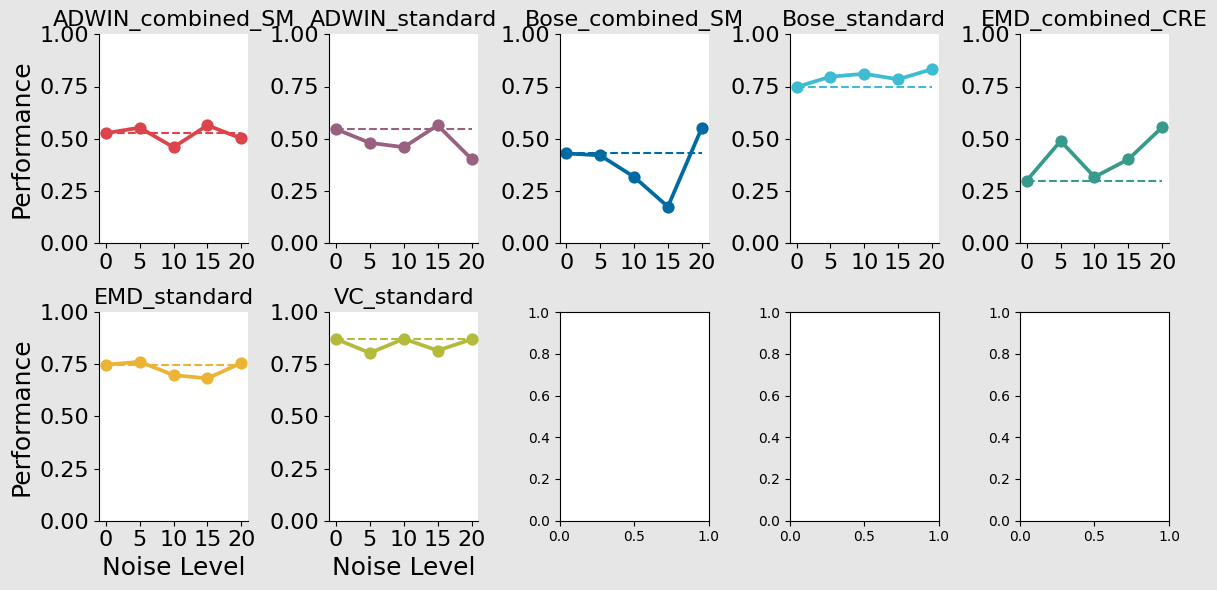

In [49]:
def plot_robustness(robustness_df, logset:str, color_map):
    fig, axs = plt.subplots(2,5, figsize=(12,6))
    #fig.suptitle(f"Robustness of Approaches for {logset} Logs")
    
    for idx, name in enumerate(robustness_df["Approach"].unique()):
        row_offset = idx // 5
        col_offset = idx % 5
        ax = axs[row_offset, col_offset]
        relevant_df = robustness_df[(robustness_df["Approach"] == name) & (robustness_df["Log Set"] == logset)]
        sns.pointplot(x="Noise Level", y="Robustness", data=relevant_df, errorbar=None,color= color_map[name], ax=ax)#, title=name)
        ax.set_ylim(0,1)
        ax.set_title(name, size = 16)
        ax.spines.right.set_visible(False)
        ax.spines.top.set_visible(False)
        ax.tick_params(labelsize=16)
        ax.set_xlabel(ax.get_xlabel() if row_offset == 1 else "", size = 18)
        ax.set_ylabel("Performance" if col_offset == 0 else "", size = 18)
        robustness_of_zero_noise = min(zip(relevant_df["Noise Level"], relevant_df["Robustness"]), key=lambda x: x[0])[1]
        if np.isnan(robustness_of_zero_noise):
            robustness_of_zero_noise = 0
        # plt.axhline(y=robustness_of_zero_noise, color='r', linestyle='-', ax=ax)
        ax.hlines(robustness_of_zero_noise, color=color_map[name], linestyle='dashed', xmin=0, xmax=len(relevant_df["Noise Level"].unique())-1)
        fig.tight_layout()
        #ax.grid()
        fig.set_facecolor('0.9')
    return fig, axs

if not os.path.exists(f"{OUT_PATH}/Robustness{LAG_WINDOW}"):
    os.makedirs(f"{OUT_PATH}/Robustness{LAG_WINDOW}")

fig_ostovar, axs_ostovar = plot_robustness(plot_df_robust, "Ostovar", color_map)
fig_ostovar.savefig(f"{OUT_PATH}/Robustness{LAG_WINDOW}/robustness_ostovar_logs.pdf", bbox_inches="tight", format="pdf")
plt.show(fig_ostovar)

fig_ceravolo, axs_ceravolo = plot_robustness(plot_df_robust, "Ceravolo", color_map)
fig_ceravolo.savefig(f"{OUT_PATH}/Robustness{LAG_WINDOW}/robustness_ceravolo_logs.pdf", bbox_inches="tight", format="pdf")
plt.show(fig_ceravolo)

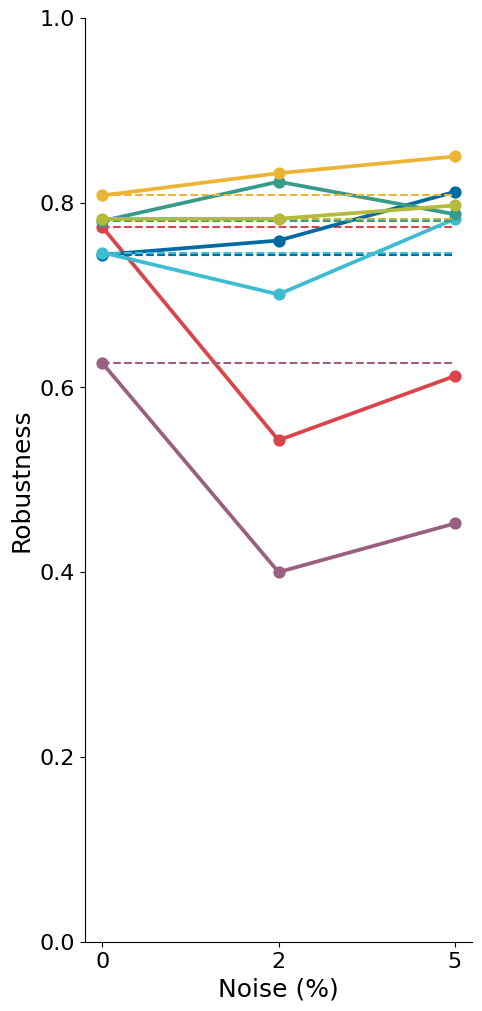

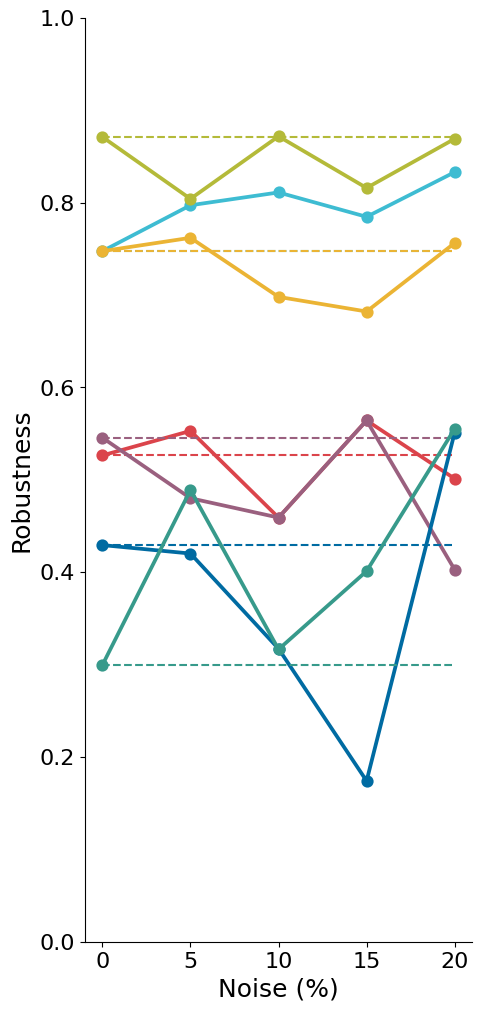

In [50]:
def plot_robustness(robustness_df, logset:str, color_map):
    
    for _, name in enumerate(robustness_df["Approach"].unique()):
        relevant_df = robustness_df[(robustness_df["Approach"] == name) & (robustness_df["Log Set"] == logset)]
        ax = sns.pointplot(x="Noise Level", y="Robustness", data=relevant_df, errorbar=None,color= color_map[name])#, title=name)
        ax.set_ylim(0,1)
        ax.figure.set_size_inches(5, 12)
        #ax.set_title(logset+" Logs with Different Noise Levels", size = 18)
        ax.set_xlabel("Noise (%)")
        ax.spines.right.set_visible(False)
        ax.spines.top.set_visible(False)
        ax.tick_params(labelsize=16)
        ax.set_xlabel(ax.get_xlabel(), size = 18)
        ax.set_ylabel(ax.get_ylabel(), size = 18)
        robustness_of_zero_noise = min(zip(relevant_df["Noise Level"], relevant_df["Robustness"]), key=lambda x: x[0])[1]
        if np.isnan(robustness_of_zero_noise):
            robustness_of_zero_noise = 0
        # plt.axhline(y=robustness_of_zero_noise, color='r', linestyle='-', ax=ax)
        ax.hlines(robustness_of_zero_noise, color=color_map[name], linestyle='dashed', xmin=0, xmax=len(relevant_df["Noise Level"].unique())-1)
    return fig

if not os.path.exists(f"{OUT_PATH}/Robustness{LAG_WINDOW}"):
    os.makedirs(f"{OUT_PATH}/Robustness{LAG_WINDOW}")

fig_ostovar = plot_robustness(plot_df_robust, "Ostovar", color_map)
fig_ostovar.savefig(f"{OUT_PATH}/Robustness{LAG_WINDOW}/robustness_ostovar_logs_all_in_one.pdf", bbox_inches="tight", format="pdf")
plt.show(fig_ostovar)

fig_ceravolo = plot_robustness(plot_df_robust, "Ceravolo", color_map)
fig_ceravolo.savefig(f"{OUT_PATH}/Robustness{LAG_WINDOW}/robustness_ceravolo_logs_all_in_one.pdf", bbox_inches="tight", format="pdf")
plt.show(fig_ceravolo)

## Save Results

In [51]:
results_df = pd.DataFrame([
    {
        "Algorithm": name,
        "Accuracy": accuracies[name],
        "Latency": (1-latencies[name])*LAG_WINDOW,
        "Versatility": versatilities[name],
        "Scalability": scalabilities[name]["str"],
        "Milliseconds per Case": seconds_per_case[name]*1000,
        "Milliseconds per Event": seconds_per_event[name]*1000,
        "Parameter Sensitivity (IQR)": sensitivity_iqrs[name],
        "Robustness": robustnesses[name]
    }
    for name in df["Algorithm"].unique()
])

results_df.to_csv(f"{OUT_PATH}/evaluation_measures{LAG_WINDOW}.csv", index=False)
results_df

,Algorithm,Accuracy,Latency,Versatility,Scalability,Milliseconds per Case,Milliseconds per Event,Parameter Sensitivity (IQR),Robustness
0,ADWIN_combined_SM,0.831169,74.218750,0.781250,00:01:15,39.200735,1.503715,0.0,0.890441
1,ADWIN_standard,0.750000,76.833333,0.572917,00:01:15,39.311652,1.507970,0.0,0.821242
2,Bose_combined_SM,0.674419,57.896552,0.666667,00:17:09,535.679900,20.548337,0.0,0.927038
3,Bose_standard,0.790123,53.500000,0.770833,00:17:09,535.637102,20.546695,0.0,1.024450
4,EMD_combined_CRE,0.765432,80.032258,0.750000,00:03:56,122.927676,4.715427,0.0,1.197028
5,EMD_standard,0.833333,51.857143,0.875000,00:03:49,119.376853,4.579219,0.0,0.999219
6,VC_standard,0.897436,71.142857,0.916667,00:00:02,1.419351,0.054445,0.0,0.985246
